# 04 — Machine Learning Model Training (Late vs Not-late Prediction)

ในสมุดบันทึกนี้ เราจะทำการสร้างโมเดล Machine Learning เพื่อตอบคำถาม:

> “เราสามารถทำนายได้หรือไม่ว่าเรื่องร้องเรียนของ Traffy Fondue จะ **เสร็จช้า (late)** หรือ **เสร็จตามเวลา**?”

## สิ่งที่จะทำใน notebook นี้

1. โหลด Feature dataset (`traffy_features.csv`)
2. แยก **features (X)** และ **target (y = is_late)**
3. สร้าง **ML Pipeline** ประกอบด้วย
   - Imputer สำหรับ missing values
   - OneHotEncoder สำหรับ categorical
   - StandardScaler สำหรับ numeric
4. Train/Test Split
5. โมเดลที่ใช้:
   - RandomForestClassifier (baseline)
6. Evaluation:
   - Accuracy
   - F1-score
   - Confusion matrix
7. Feature importance
8. เซฟโมเดลเป็น `.joblib`

ผลสุดท้ายจะพร้อมใช้ในการ deploy หรือการอธิบายในรายงาน


In [2]:
import os
import pandas as pd
import numpy as np

# ML
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

import seaborn as sns
import matplotlib.pyplot as plt

import joblib

# Paths
BASE_DIR = os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, "data")
FEATURE_DIR = os.path.join(DATA_DIR, "features")

FEATURE_FILE = os.path.join(FEATURE_DIR, "data_2024.csv")
MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

In [7]:
df_2024 = pd.read_csv(FEATURE_FILE)
print("Loaded:", df_2024.shape)
df_2024.head()

Loaded: (307231, 27)


,ticket_id,type,organization,comment,district,timestamp,star,count_reopen,day,hour,...,congestion,report_hour,datetime,temp,rain_volume,wind_speed,temp_volatility_6h,wind_range_3h,isTempVolatility,isGustsWind
0,2024-7DGA4F,{คลอง},"เขตตลิ่งชัน,เขตบางกอกน้อย,ฝ่ายสิ่งแวดล้อมฯ เขต...",พบการปล่อยน้ำเสีย จากบ้านเรือนลงสู่คลอง,ตลิ่งชัน,2024-01-01 00:07:06.679724,5.0,0,Mon,0,...,0,2024-01-01 00:00:00,2024-01-01 00:00:00,27.2,0.0,10.9,NaN,NaN,0,0
1,2024-BWARW3,{เสียงรบกวน},"เขตวังทองหลาง,ฝ่ายสิ่งแวดล้อมฯ เขตวังทองหลาง,ก...",เพื่อนบ้านมีการรวมตัวฉลองเปิดเพลงเสียงดังมาก *...,วังทองหลาง,2024-01-01 00:10:03.752741,5.0,0,Mon,0,...,0,2024-01-01 00:00:00,2024-01-01 00:00:00,27.2,0.0,10.9,NaN,NaN,0,0
2,2024-GYHTAZ,{},"เขตราชเทวี,ฝ่ายเทศกิจ เขตราชเทวี",ร้านก๋วยเตี๋ยวหมูขายของเสร็จน้ำ เน่า เยอะไปหมด...,ราชเทวี,2024-01-01 00:45:41.359687,0.0,0,Mon,0,...,0,2024-01-01 00:00:00,2024-01-01 00:00:00,27.2,0.0,10.9,NaN,0.0,0,0
3,2024-82WG33,{ความสะอาด},"เขตสวนหลวง,สำนักสิ่งแวดล้อม กทม.,ฝ่ายสิ่งแวดล้...",พื้นที่ว่างของวัดใต้ลักลอบเผาขยะเป็นประจำโดยเฉ...,สวนหลวง,2024-01-01 01:00:45.543968,0.0,0,Mon,1,...,0,2024-01-01 01:00:00,2024-01-01 01:00:00,26.3,0.0,10.5,NaN,0.4,0,0
4,2024-ATTVT4,{},"เขตบางแค,สน.เพชรเกษม,สำนักงานตำรวจแห่งชาติ (Ro...",เมื่อคืนเวลาเที่ยงคืน ร้านYves.bkk rooftop จุด...,บางแค,2024-01-01 01:13:50.110268,1.0,0,Mon,1,...,0,2024-01-01 01:00:00,2024-01-01 01:00:00,26.3,0.0,10.5,NaN,0.4,0,0


In [ ]:
feature_cols = [
    # categorical (จะ one-hot ในขั้น ML)
    "urgency_score",
    "organization",
    "district",

    # location
    "lat",
    "lon",

    # ticket behavior
    "star",
    "count_reopen",

    # time features
    "hour",
    "dayofweek",
    "month",
    "year",

    # weather features
    "rain_volume",
    "temp",
    "wind_speed",
    "isTempVolatility",
    "isGustsWind",

    # target
    "isLate",
]
feature_cols_existing = [c for c in feature_cols if c in df_2024.columns]

df_features = df_2024[feature_cols_existing].copy()
# logger.info(f"Final feature table shape: {df_features.shape}")
df_features.head()

,type,organization,district,lat,lon,star,count_reopen,hour,month,year,rain_volume,temp,wind_speed,isTempVolatility,isGustsWind,isLate
0,{คลอง},"เขตตลิ่งชัน,เขตบางกอกน้อย,ฝ่ายสิ่งแวดล้อมฯ เขต...",ตลิ่งชัน,100.46033,13.75419,5.0,0,0,1,2024,0.0,27.2,10.9,0,0,0
1,{เสียงรบกวน},"เขตวังทองหลาง,ฝ่ายสิ่งแวดล้อมฯ เขตวังทองหลาง,ก...",วังทองหลาง,100.61698,13.78799,5.0,0,0,1,2024,0.0,27.2,10.9,0,0,0
2,{},"เขตราชเทวี,ฝ่ายเทศกิจ เขตราชเทวี",ราชเทวี,100.52951,13.75178,0.0,0,0,1,2024,0.0,27.2,10.9,0,0,1
3,{ความสะอาด},"เขตสวนหลวง,สำนักสิ่งแวดล้อม กทม.,ฝ่ายสิ่งแวดล้...",สวนหลวง,100.60225,13.71287,0.0,0,1,1,2024,0.0,26.3,10.5,0,0,0
4,{},"เขตบางแค,สน.เพชรเกษม,สำนักงานตำรวจแห่งชาติ (Ro...",บางแค,100.41546,13.68437,1.0,0,1,1,2024,0.0,26.3,10.5,0,0,0


In [9]:
target = "isLate"

# X = all columns except target
X = df_features.drop(columns=[target])
y = df_features[target]

print(X.shape, y.shape)
X.head()

(307231, 15) (307231,)


,type,organization,district,lat,lon,star,count_reopen,hour,month,year,rain_volume,temp,wind_speed,isTempVolatility,isGustsWind
0,{คลอง},"เขตตลิ่งชัน,เขตบางกอกน้อย,ฝ่ายสิ่งแวดล้อมฯ เขต...",ตลิ่งชัน,100.46033,13.75419,5.0,0,0,1,2024,0.0,27.2,10.9,0,0
1,{เสียงรบกวน},"เขตวังทองหลาง,ฝ่ายสิ่งแวดล้อมฯ เขตวังทองหลาง,ก...",วังทองหลาง,100.61698,13.78799,5.0,0,0,1,2024,0.0,27.2,10.9,0,0
2,{},"เขตราชเทวี,ฝ่ายเทศกิจ เขตราชเทวี",ราชเทวี,100.52951,13.75178,0.0,0,0,1,2024,0.0,27.2,10.9,0,0
3,{ความสะอาด},"เขตสวนหลวง,สำนักสิ่งแวดล้อม กทม.,ฝ่ายสิ่งแวดล้...",สวนหลวง,100.60225,13.71287,0.0,0,1,1,2024,0.0,26.3,10.5,0,0
4,{},"เขตบางแค,สน.เพชรเกษม,สำนักงานตำรวจแห่งชาติ (Ro...",บางแค,100.41546,13.68437,1.0,0,1,1,2024,0.0,26.3,10.5,0,0


In [10]:
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

Numeric: ['lat', 'lon', 'star', 'count_reopen', 'hour', 'month', 'year', 'rain_volume', 'temp', 'wind_speed', 'isTempVolatility', 'isGustsWind']
Categorical: ['type', 'organization', 'district']


In [11]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [12]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    random_state=42
)

clf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", model)
])

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((245784, 15), (61447, 15))

In [14]:
clf.fit(X_train, y_train)
print("Training complete.")

Training complete.


Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.84      0.79     34235
           1       0.76      0.63      0.69     27212

    accuracy                           0.75     61447
   macro avg       0.75      0.74      0.74     61447
weighted avg       0.75      0.75      0.74     61447



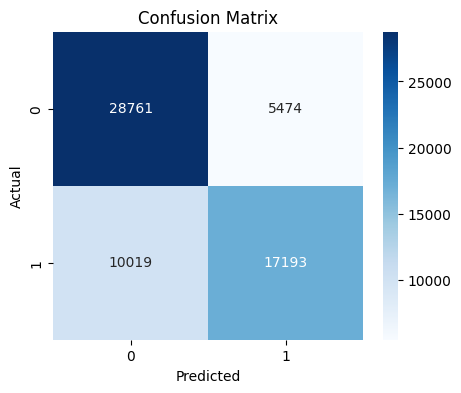

In [15]:
y_pred = clf.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [16]:
# get feature names
ohe = clf.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
ohe_features = ohe.get_feature_names_out(categorical_cols)

all_features = np.concatenate([numeric_cols, ohe_features])

importances = clf.named_steps["model"].feature_importances_

feat_df = pd.DataFrame({
    "feature": all_features,
    "importance": importances
}).sort_values(by="importance", ascending=False)

feat_df.head(20)

,feature,importance
0,lat,0.076312
1,lon,0.074475
9,wind_speed,0.065967
8,temp,0.064620
4,hour,0.051200
5,month,0.050878
3,count_reopen,0.023742
2,star,0.020860
7,rain_volume,0.019820
8695,type_{แสงสว่าง},0.009218


In [21]:
X.head()

,type,organization,district,lat,lon,star,count_reopen,hour,month,year,rain_volume,temp,wind_speed,isTempVolatility,isGustsWind
0,{คลอง},"เขตตลิ่งชัน,เขตบางกอกน้อย,ฝ่ายสิ่งแวดล้อมฯ เขต...",ตลิ่งชัน,100.46033,13.75419,5.0,0,0,1,2024,0.0,27.2,10.9,0,0
1,{เสียงรบกวน},"เขตวังทองหลาง,ฝ่ายสิ่งแวดล้อมฯ เขตวังทองหลาง,ก...",วังทองหลาง,100.61698,13.78799,5.0,0,0,1,2024,0.0,27.2,10.9,0,0
2,{},"เขตราชเทวี,ฝ่ายเทศกิจ เขตราชเทวี",ราชเทวี,100.52951,13.75178,0.0,0,0,1,2024,0.0,27.2,10.9,0,0
3,{ความสะอาด},"เขตสวนหลวง,สำนักสิ่งแวดล้อม กทม.,ฝ่ายสิ่งแวดล้...",สวนหลวง,100.60225,13.71287,0.0,0,1,1,2024,0.0,26.3,10.5,0,0
4,{},"เขตบางแค,สน.เพชรเกษม,สำนักงานตำรวจแห่งชาติ (Ro...",บางแค,100.41546,13.68437,1.0,0,1,1,2024,0.0,26.3,10.5,0,0


C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 3626 (\N{THAI CHARACTER SO SUA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 3

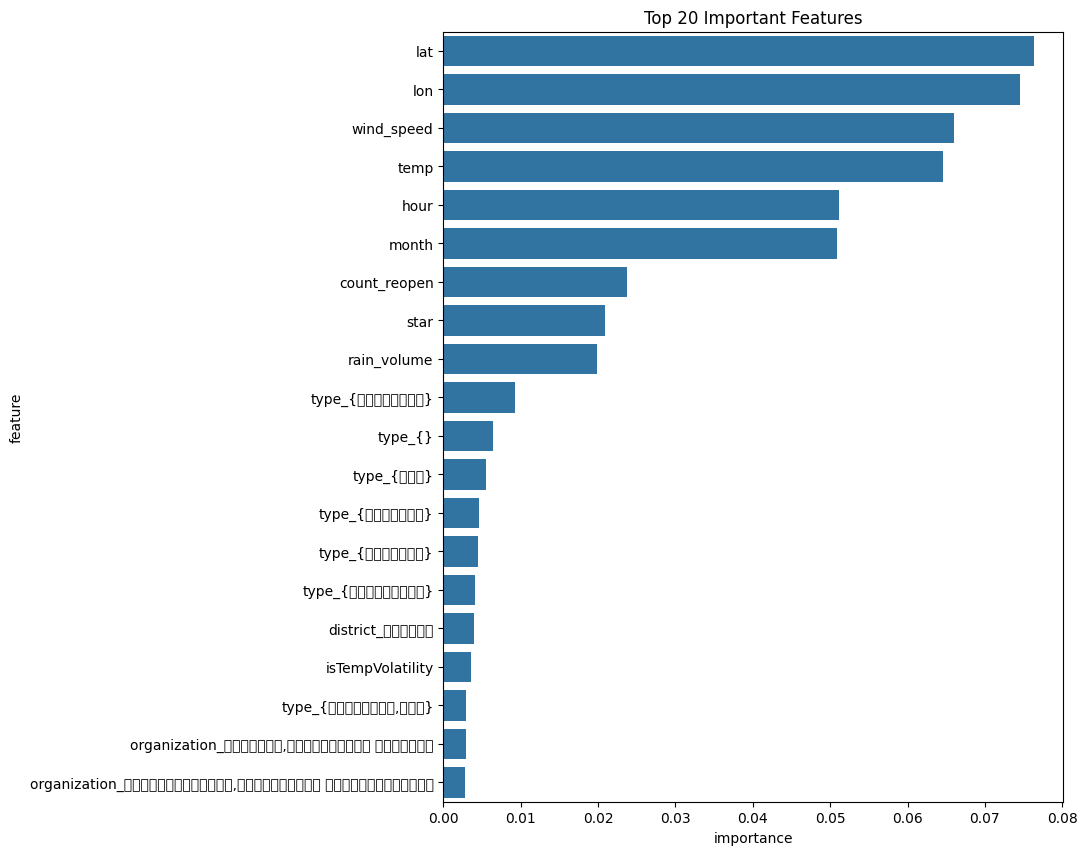

In [17]:
plt.figure(figsize=(8,10))
sns.barplot(data=feat_df.head(20), x="importance", y="feature")
plt.title("Top 20 Important Features")
plt.show()

In [18]:
model_path = os.path.join(MODEL_DIR, "traffy_rf_model.joblib")
joblib.dump(clf, model_path)

print("Model saved to:", model_path)

Model saved to: d:\CEDT\DataSci\projek\models\traffy_rf_model.joblib


In [ ]:
# Batch prediction on the entire dataset used for training
df_features["pred_is_late"] = clf.predict(X)
df_features["pred_proba_late"] = clf.predict_proba(X)[:, 1]

# Save output for Power BI
out_path = "./data/predictions/traffy_with_predictions.csv"
os.makedirs("./data/predictions", exist_ok=True)
df_features.to_csv(out_path, index=False, encoding="utf-8-sig")

print("✔ Batch predictions saved to:", out_path)

✔ Batch predictions saved to: ../data/predictions/traffy_with_predictions.csv


# Summary — ML Model Training Completed

สิ่งที่ทำใน `04_ml_training.ipynb`:

1. โหลดฟีเจอร์จาก `traffy_features.csv`
2. แยก X (features) และ y (target = is_late)
3. สร้าง Preprocessing Pipeline:
   - Imputer (numeric/categorical)
   - StandardScaler (numeric)
   - OneHotEncoder (categorical)
4. เทรนโมเดล RandomForestClassifier
5. ประเมินผลด้วย classification report และ confusion matrix
6. วิเคราะห์ feature importance
7. บันทึกโมเดลเป็น `traffy_rf_model.joblib`